# Notebook 14 - EDA Mini Challenge
Sprint 4 - EDA

**Dataset:** Titanic passenger data (Kaggle, Titanic - Machine Learning from Disaster, file train.csv)

In this mini challenge I explore a dataset on my own without step by step instructions. I follow the sprint workflow:

Load, Inspect, Understand, Analyze, Visualize, Identify Problems, Document Findings

I load the data, understand and inspect it, check its quality, analyze the numerical and categorical features, look for outliers, distributions and correlations, study the target, create meaningful visualizations, write insights and finally recommend what to do in the preprocessing stage. I do not clean or change the data in this notebook, I only find and document the problems.

## 1. About the dataset

| Item | Details |
|---|---|
| Name | Titanic passenger data (training file) |
| Source | Kaggle competition Titanic - Machine Learning from Disaster, file train.csv |
| Domain | Passenger transport and safety (a historical disaster, the sinking of the ship on 15 April 1912) |
| One row represents | One passenger |
| Rows | 891 |
| Columns | 12 |
| Target variable | Survived (0 = did not survive, 1 = survived), so this is a binary classification problem |
| Identifier columns | PassengerId, Name, Ticket |

**Data dictionary**

| Column | Meaning |
|---|---|
| PassengerId | Running number of the passenger |
| Survived | 0 = did not survive, 1 = survived (target) |
| Pclass | Ticket class: 1 = first, 2 = second, 3 = third (a sign of social and economic status) |
| Name | Name of the passenger, including a title such as Mr or Mrs |
| Sex | male or female |
| Age | Age in years (fractions for babies) |
| SibSp | Number of siblings or spouses travelling with the passenger |
| Parch | Number of parents or children travelling with the passenger |
| Ticket | Ticket number |
| Fare | Price paid for the ticket |
| Cabin | Cabin number |
| Embarked | Port of boarding: C = Cherbourg, Q = Queenstown, S = Southampton |

**Business question:** Which passengers were more likely to survive, and what does it say about how the evacuation worked? In machine learning terms: which features can help to predict Survived?

## 2. Load the dataset

**Concept:** Loading means reading the file into a pandas DataFrame, which is a table with rows (records) and columns (variables). The first look at the data tells me what one row stands for and what kind of values the columns hold.

**Example:** A shop keeps its sales in a csv file. After loading it, each row is one sale and the columns are product, price and date.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statistics import NormalDist

sns.set_style("whitegrid")

# the file train.csv must be in the same folder as this notebook
df = pd.read_csv("train.csv")

print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**What the code does:** It imports the libraries, reads train.csv into a DataFrame called df, prints the shape and shows the first five rows.

**Why this method was used:** read_csv is the standard way to load a csv file, and head shows what the records look like before I do any calculation.

**What the output means:** The data has 891 rows and 12 columns. Each row is one passenger, and some cells in Cabin are empty (NaN).

**Insights:** The data mixes numbers (Age, Fare), labels (Sex, Embarked) and text (Name, Ticket, Cabin), and the target Survived is already coded as 0 and 1.

**Effect on the ML pipeline:** Everything later depends on this DataFrame. The target is already numeric, so the problem can be treated directly as binary classification.

## 3. Understand the dataset

**Concept:** Before analysing, I must know what each column is.
- A **feature** is a column that describes a record and can be used as an input of a model.
- The **target** is the column I want to predict. It is the dependent variable, and the features are the independent variables.
- An **identifier** is a column that gives a unique label to each record (like a roll number). It does not help to predict anything.
- **Numerical** features hold quantities (age, price), and **categorical** features hold groups (sex, port). A numerical feature is **discrete** when it counts whole things (number of siblings) and **continuous** when it can take any value in a range (fare).

**Example:** In a table of house prices, the area of the house is a continuous feature, the number of bedrooms is a discrete feature, the city is categorical, the house number is an identifier and the price is the target.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
print(df.dtypes)
print()
print("Unique values in each column:")
print(df.nunique().sort_values())

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Unique values in each column:
Survived         2
Sex              2
Pclass           3
Embarked         3
Parch            7
SibSp            7
Age             88
Cabin          147
Fare           248
Ticket         681
PassengerId    891
Name           891
dtype: int64


**What the code does:** info prints the number of non-null values and the data type of each column, and nunique counts the different values in each column.

**Why this method was used:** Together they show the data types, the missing values and which columns have few or many different values, which helps me decide the type of each column.

**What the output means:** Age has 714 non-null values, Cabin has only 204 and Embarked has 889, so these three have missing values. Name has 891 unique values and PassengerId also has 891, so both are unique for every passenger. Ticket has about 681 unique values and Cabin about 147. Survived, Sex, Pclass and Embarked have very few unique values.

**Insights:** The columns with very few unique values (Survived, Sex, Pclass, Embarked, and also SibSp and Parch) behave like categories or small counts. Name, Ticket and Cabin have many different values, so they are text or identifier like columns.

**Effect on the ML pipeline:** Columns with many unique text values cannot be one-hot encoded directly. They must be dropped or turned into simpler features, for example a title from the name.

Now I classify the columns by their meaning and not only by the stored data type.

In [5]:
target = "Survived"
identifier_cols = ["PassengerId", "Name", "Ticket"]
numerical_continuous = ["Age", "Fare"]
numerical_discrete = ["SibSp", "Parch"]
categorical_cols = ["Pclass", "Sex", "Embarked"]
high_missing_text = ["Cabin"]

print("Target:", target)
print("Identifier or text columns:", identifier_cols)
print("Continuous numerical:", numerical_continuous)
print("Discrete numerical (counts):", numerical_discrete)
print("Categorical:", categorical_cols)
print("Mostly missing text column:", high_missing_text)

Target: Survived
Identifier or text columns: ['PassengerId', 'Name', 'Ticket']
Continuous numerical: ['Age', 'Fare']
Discrete numerical (counts): ['SibSp', 'Parch']
Categorical: ['Pclass', 'Sex', 'Embarked']
Mostly missing text column: ['Cabin']


**Why I classified them like this:**
- Pclass is stored as a number but it only means first, second or third class, so it is an ordered category (ordinal).
- SibSp and Parch are counts of relatives. They are discrete numerical features, with most values at 0.
- PassengerId, Name and Ticket identify a passenger or a ticket and do not describe a property that generalizes, so I treat them as identifiers. Name still contains a title (Mr, Mrs, Miss) that may carry information, which I explore later.
- Cabin is a text column that is mostly empty.

## 4. Inspect the data

**Concept:** Data inspection means looking at the real rows and at summary statistics. head shows the first rows, tail the last rows, sample random rows, and describe gives count, mean, standard deviation, minimum, quartiles and maximum.

**Example:** If a sales file is sorted by date, head shows the oldest records and tail the newest ones. A random sample is a fairer picture of the whole.

In [6]:
display_cols = ["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
print("Last 5 rows")
print(df.tail())
print()
print("5 random rows")
print(df.sample(5, random_state=42))

Last 5 rows
     PassengerId  Survived  Pclass                                      Name  \
886          887         0       2                     Montvila, Rev. Juozas   
887          888         1       1              Graham, Miss. Margaret Edith   
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"   
889          890         1       1                     Behr, Mr. Karl Howell   
890          891         0       3                       Dooley, Mr. Patrick   

        Sex   Age  SibSp  Parch      Ticket   Fare Cabin Embarked  
886    male  27.0      0      0      211536  13.00   NaN        S  
887  female  19.0      0      0      112053  30.00   B42        S  
888  female   NaN      1      2  W./C. 6607  23.45   NaN        S  
889    male  26.0      0      0      111369  30.00  C148        C  
890    male  32.0      0      0      370376   7.75   NaN        Q  

5 random rows
     PassengerId  Survived  Pclass  \
709          710         1       3   
439     

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [8]:
df.describe(exclude="number").T

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


**What the code does:** tail and sample show the last rows and five random rows. describe gives the summary statistics of the numerical columns, and describe with exclude set to number gives count, unique values, the most frequent value and its frequency for the text columns.

**Why this method was used:** The statistics show the scale and spread of each column, and the text summary shows which labels are the most common.

**What the output means:** Survived has a mean of about 0.38, so about 38 percent of the passengers survived. The mean age is about 29.7 years with a median of 28. The mean fare is about 32 while the median is only about 14.5, and the maximum is about 512. SibSp and Parch are 0 for most passengers. For the text columns, male is the most common value of Sex (577 passengers), and S is the most common port.

**Insights:** The big gap between the mean fare and the median fare, and the very large maximum, show that Fare is strongly skewed to the right. The ages look natural, from a baby of about 5 months to 80 years.

**Effect on the ML pipeline:** The columns are on very different scales (Fare goes up to 512, Pclass only up to 3), so scaling will matter for distance based and gradient based models.

## 5. Missing values

**Concept:** A missing value is a place where a value should be present but is not. In pandas it appears as NaN, and isnull().sum() counts it. What matters is the percentage of missing values in a column and the pattern: values can be missing completely at random, or because of a reason connected with other columns, and in that case the missingness itself carries information.

**Example:** In a hospital table, the blood sugar value is missing for patients who were never tested. Filling it with the average would hide the fact that those patients are different.

          missing  percent
Cabin         687    77.10
Age           177    19.87
Embarked        2     0.22


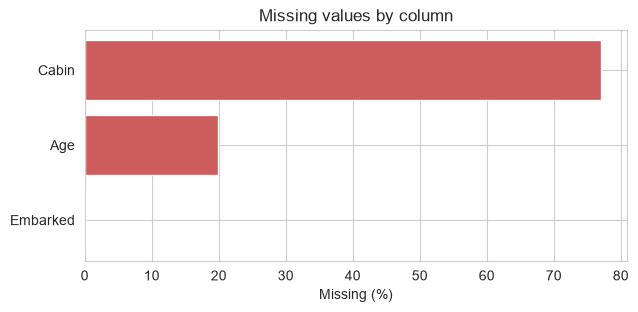

In [9]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_table = missing_table[missing_table["missing"] > 0].sort_values("missing", ascending=False)
print(missing_table)

plt.figure(figsize=(7, 3))
plt.barh(missing_table.index[::-1], missing_table["percent"][::-1], color="indianred")
plt.xlabel("Missing (%)")
plt.title("Missing values by column")
plt.show()

In [10]:
# is the missingness connected with other columns?
print("Passengers with a missing Age, by class:")
print(df[df["Age"].isnull()]["Pclass"].value_counts().sort_index())
print()
print("Survival rate (%) when Age is missing or present:")
print((df.groupby(df["Age"].isnull())["Survived"].mean() * 100).round(1))
print()
print("Survival rate (%) when Cabin is known or not:")
print((df.groupby(df["Cabin"].notnull())["Survived"].mean() * 100).round(1))

Passengers with a missing Age, by class:
Pclass
1     30
2     11
3    136
Name: count, dtype: int64

Survival rate (%) when Age is missing or present:
Age
False    40.6
True     29.4
Name: Survived, dtype: float64

Survival rate (%) when Cabin is known or not:
Cabin
False    30.0
True     66.7
Name: Survived, dtype: float64


**What the code does:** The first cell counts the missing values in each column, calculates the percentage and draws a bar chart. The second cell checks the class of the passengers with a missing Age, and compares the survival rate of passengers with and without a missing Age and a known or unknown Cabin.

**Why this method was used:** The count and the percentage show how serious the problem is. Comparing the groups checks whether the missingness has a pattern, because that decides how it should be treated.

**What the output means:** Cabin is missing for 687 passengers (about 77 percent), Age for 177 (about 20 percent) and Embarked for only 2 (about 0.2 percent). Most of the missing ages (136 of 177) belong to third class passengers. The survival rate of passengers with a known cabin is much higher (about 67 percent) than that of passengers with an unknown cabin (about 30 percent), and passengers with a missing age also survived less (about 29 percent compared with about 41 percent).

**Insights:** The missing values are not random. Cabin was mostly recorded for first class passengers, and many of the third class passengers have no age or cabin. So whether a value is missing is related to class and to survival. The Embarked column has only two missing values, which is not a serious problem.

**Effect on the ML pipeline:** Cabin is too empty to impute, but a simple yes or no column (cabin known) might be useful. Age should be imputed carefully, for example with the median inside groups, and it may be useful to keep a missing indicator. Embarked can be filled with the most common port. These will be done in the preprocessing sprint.

## 6. Duplicate records

**Concept:** A duplicate record is a row that appears more than once. A completely duplicated row is identical in every column. Duplicates can make some records count twice in a model and can leak the same record into both the training and the test set.

**Example:** If an order is saved twice by mistake, the total sales are counted twice.

In [11]:
print("Completely duplicated rows:", df.duplicated().sum())
print("Duplicate PassengerId:", df["PassengerId"].duplicated().sum())
print("Duplicate Name:", df["Name"].duplicated().sum())

# tickets used by more than one passenger
ticket_counts = df["Ticket"].value_counts()
shared = ticket_counts[ticket_counts > 1]
print()
print("Tickets used by more than one passenger:", len(shared))
print("Passengers who share a ticket:", int(shared.sum()))

# do passengers on the same ticket pay the same fare?
same_fare = df[df["Ticket"].isin(shared.index)].groupby("Ticket")["Fare"].nunique()
print("Shared tickets where everyone has the same fare:", int((same_fare == 1).sum()), "of", len(same_fare))

Completely duplicated rows: 0
Duplicate PassengerId: 0
Duplicate Name: 0

Tickets used by more than one passenger: 134
Passengers who share a ticket: 344
Shared tickets where everyone has the same fare: 133 of 134


**What the code does:** It counts completely duplicated rows, duplicated ids and names, and the tickets that are used by more than one passenger. It also checks whether passengers on a shared ticket have the same fare.

**Why this method was used:** A full duplicate check finds repeated rows, and looking at the ticket shows a repetition that is not a duplicate row but may matter for the analysis.

**What the output means:** There are no completely duplicated rows and no repeated PassengerId or Name. A good number of passengers share a ticket with others, and almost all shared tickets show the same fare for everyone on the ticket.

**Insights:** No row has to be removed. Passengers who share a ticket are mostly families or travelling groups. The same fare on a shared ticket suggests that the Fare column may show the price of the whole ticket and not the price for one person.

**Effect on the ML pipeline:** No deduplication is needed. Because related passengers can have the same ticket, a random split can put family members in both the training and the test set, which can make a model look better than it is. A fare per person feature could also be considered.

## 7. Invalid and unexpected values

**Concept:** Invalid values are values that are impossible or not allowed for the column, such as negative ages or wrong category labels. Unexpected values are possible but unusual and need a check, for example a ticket price of zero.

**Example:** In a table of employees, an age of 250 is impossible and must be an error, while a salary of zero might be an intern or a data error and must be checked.

In [12]:
print("Negative values in numerical columns:")
print((df[["Age", "SibSp", "Parch", "Fare"]] < 0).sum())
print()
print("Age range:", df["Age"].min(), "to", df["Age"].max())
print("Passengers younger than 1 year:", (df["Age"] < 1).sum())
print("Passengers with Fare equal to 0:", (df["Fare"] == 0).sum())
print()
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(col, "->", sorted(df[col].dropna().unique().tolist()))
print()
print("SibSp values:", sorted(df["SibSp"].unique().tolist()))
print("Parch values:", sorted(df["Parch"].unique().tolist()))

Negative values in numerical columns:
Age      0
SibSp    0
Parch    0
Fare     0
dtype: int64

Age range: 0.42 to 80.0
Passengers younger than 1 year: 7
Passengers with Fare equal to 0: 15

Survived -> [0, 1]
Pclass -> [1, 2, 3]
Sex -> ['female', 'male']
Embarked -> ['C', 'Q', 'S']

SibSp values: [0, 1, 2, 3, 4, 5, 8]
Parch values: [0, 1, 2, 3, 4, 5, 6]


In [13]:
df[df["Fare"] == 0][["Name", "Pclass", "Sex", "Age", "Embarked", "Survived"]]

,Name,Pclass,Sex,Age,Embarked,Survived
179,"Leonard, Mr. Lionel",3,male,36.0,S,0
263,"Harrison, Mr. William",1,male,40.0,S,0
271,"Tornquist, Mr. William Henry",3,male,25.0,S,1
277,"Parkes, Mr. Francis ""Frank""",2,male,NaN,S,0
302,"Johnson, Mr. William Cahoone Jr",3,male,19.0,S,0
413,"Cunningham, Mr. Alfred Fleming",2,male,NaN,S,0
466,"Campbell, Mr. William",2,male,NaN,S,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,male,NaN,S,0
597,"Johnson, Mr. Alfred",3,male,49.0,S,0
633,"Parr, Mr. William Henry Marsh",1,male,NaN,S,0


**What the code does:** It counts negative values in the numerical columns, shows the age range, counts babies and passengers with a fare of zero, and lists the allowed values of the categorical columns and of SibSp and Parch. The last cell lists the passengers with a fare of zero.

**Why this method was used:** These checks find impossible values and category problems, and the list of zero fares lets me look at the unusual rows directly.

**What the output means:** There are no negative values. The ages go from a baby of less than one year to 80 years, so they are possible. The categorical columns contain only the expected labels (0 and 1, classes 1 to 3, male and female, and the ports C, Q and S). SibSp goes up to 8 and Parch up to 6. There are 15 passengers with a fare of zero.

**Insights:** There are no invalid values. The zero fares are unusual but possible, because some passengers may have been crew members, guests or travelling on a free ticket, or the fare may not have been recorded. I cannot tell which from the data.

**Effect on the ML pipeline:** No row has to be removed for invalid values. The zero fares should be remembered when the fare is transformed, because a logarithm needs a positive value, so a log of one plus the fare is safer.

## 8. Univariate analysis of the numerical features

**Concept:** Univariate analysis studies one variable at a time.
- **Mean, median and mode** describe the center. When the mean is far from the median, the data is skewed or has extreme values.
- **Range, variance, standard deviation and IQR** describe the spread.
- **Skewness** measures asymmetry (positive means a long right tail), and **kurtosis** measures heavy tails and peakedness.
- A **histogram** shows the shape, and a **box plot** shows the median, the quartiles and possible outliers.

**Example:** Five salaries of 30k, 32k, 35k, 38k and 300k have a mean of 87k and a median of 35k. The median describes a typical employee better, because one very high salary pulls the mean up.

In [14]:
num_features = ["Age", "Fare", "SibSp", "Parch"]

rows = []
for col in num_features:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    rows.append([col, len(s), round(s.mean(), 2), s.median(), s.mode()[0], round(s.std(), 2), round(s.var(), 2),
                 s.min(), s.max(), round(s.max() - s.min(), 2), q1, q3, round(q3 - q1, 2),
                 round(s.skew(), 2), round(s.kurt(), 2)])

stats = pd.DataFrame(rows, columns=["feature", "count", "mean", "median", "mode", "std", "variance", "min", "max",
                                    "range", "Q1", "Q3", "IQR", "skewness", "kurtosis"])
stats

,feature,count,mean,median,mode,std,variance,min,max,range,Q1,Q3,IQR,skewness,kurtosis
0,Age,714,29.70,28.0000,24.00,14.53,211.02,0.42,80.0000,79.58,20.1250,38.0,17.88,0.39,0.18
1,Fare,891,32.20,14.4542,8.05,49.69,2469.44,0.00,512.3292,512.33,7.9104,31.0,23.09,4.79,33.40
2,SibSp,891,0.52,0.0000,0.00,1.10,1.22,0.00,8.0000,8.00,0.0000,1.0,1.00,3.70,17.88
3,Parch,891,0.38,0.0000,0.00,0.81,0.65,0.00,6.0000,6.00,0.0000,0.0,0.00,2.75,9.78


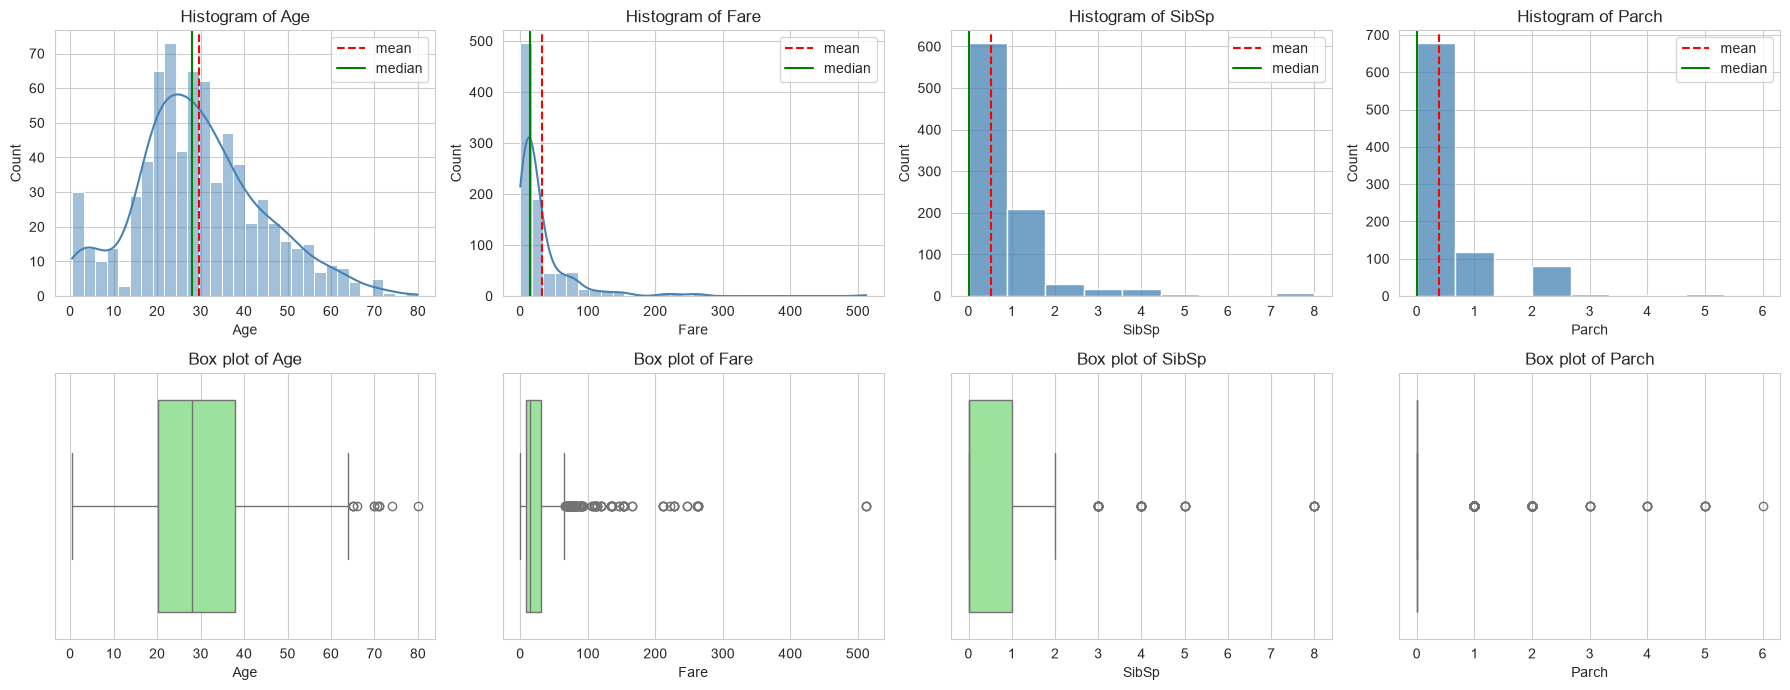

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(num_features):
    sns.histplot(df[col].dropna(), kde=(col in ["Age", "Fare"]), ax=axes[0, i], color="steelblue", bins=30 if col in ["Age", "Fare"] else 9)
    axes[0, i].axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    axes[0, i].axvline(df[col].median(), color="green", label="median")
    axes[0, i].set_title("Histogram of " + col)
    axes[0, i].legend()
    sns.boxplot(x=df[col], ax=axes[1, i], color="lightgreen")
    axes[1, i].set_title("Box plot of " + col)
plt.tight_layout()
plt.show()

**What the code does:** The first cell calculates the main statistics for Age, Fare, SibSp and Parch. The second cell draws a histogram (with a KDE curve for the continuous features and lines for the mean and the median) and a box plot for each of them.

**Why this method was used:** The statistics give exact numbers, and the two plots show the shape and the extreme values. A KDE curve is only useful for continuous data, so I did not use it for the counts SibSp and Parch.

**What the output means:** Age has a mean of about 29.7 and a median of 28, a standard deviation of about 14.5, and a skewness of about 0.39, so it is close to symmetric with a slightly longer right tail. Fare has a mean of about 32 and a median of about 14.5, a standard deviation of about 50, a skewness of about 4.8 and a kurtosis above 30, so it is extremely right skewed with a few very large values. SibSp and Parch have a median and a mode of 0 and a few large values.

**Insights:** Age looks like a bell with a small group of babies and children on the left and a few old passengers on the right. Fare is very concentrated at low prices with a long tail up to 512, so the mean is not a good description of a typical fare. Most passengers travelled without any sibling, spouse, parent or child.

**Effect on the ML pipeline:** Fare will need a transformation (for example log) for models that are sensitive to skew, and the features will need scaling because of their very different ranges. SibSp and Parch may work better combined into one family size feature.

## 9. Univariate analysis of the categorical features

**Concept:** For a categorical feature I look at the number of unique categories (cardinality), the frequency of each category (value counts) and its percentage. A bar chart or count plot shows the sizes of the categories. A pie chart is only suitable when there are few categories and the aim is to show shares of a whole.

**Example:** In a shop, if 70 percent of payments are UPI, 20 percent card and 10 percent cash, the shop knows which payment system matters most.

In [16]:
cat_features = ["Survived", "Pclass", "Sex", "Embarked"]

for col in cat_features:
    counts = df[col].value_counts(dropna=False)
    table = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})
    print(col)
    print(table)
    print()

print("Number of unique values: Name", df["Name"].nunique(), "| Ticket", df["Ticket"].nunique(), "| Cabin", df["Cabin"].nunique())

Survived
          count  percent
Survived                
0           549     61.6
1           342     38.4

Pclass
        count  percent
Pclass                
3         491     55.1
1         216     24.2
2         184     20.7

Sex
        count  percent
Sex                   
male      577     64.8
female    314     35.2

Embarked
          count  percent
Embarked                
S           644     72.3
C           168     18.9
Q            77      8.6
NaN           2      0.2

Number of unique values: Name 891 | Ticket 681 | Cabin 147


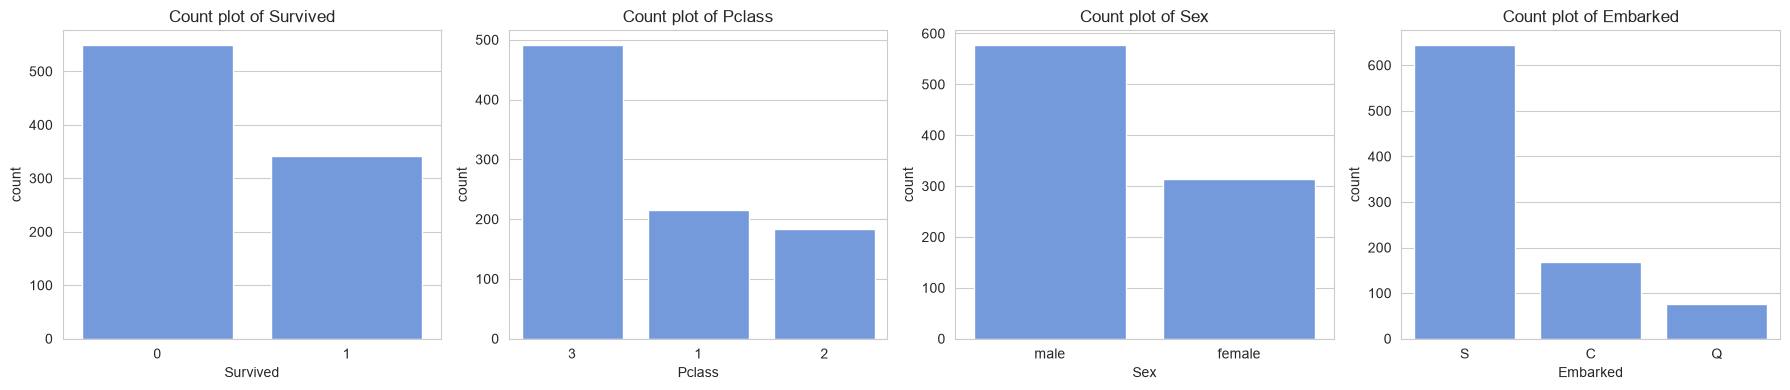

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_features):
    sns.countplot(data=df, x=col, ax=ax, color="cornflowerblue", order=df[col].value_counts().index)
    ax.set_title("Count plot of " + col)
plt.tight_layout()
plt.show()

**What the code does:** The first cell prints the count and percentage of every category of the four categorical columns and the number of unique values of Name, Ticket and Cabin. The second cell draws a count plot for each of the four columns, with the bars sorted by size.

**Why this method was used:** Value counts give exact shares, and count plots show the size differences at a glance. A pie chart was not needed because a bar shows the same information clearly.

**What the output means:** About 62 percent of the passengers did not survive and 38 percent survived. Third class has 491 passengers (about 55 percent), first class 216 and second class 184. There are 577 men (about 65 percent) and 314 women. About 72 percent of the passengers boarded in Southampton, about 19 percent in Cherbourg and about 9 percent in Queenstown. Name is unique for every passenger, and Ticket and Cabin have many different values.

**Insights:** The ship was mostly carrying third class passengers and men. The categories are all large enough to analyze, and the smallest port has 77 passengers. The target is mildly imbalanced. Name, Ticket and Cabin have high cardinality.

**Effect on the ML pipeline:** The categorical features with few categories (Pclass, Sex, Embarked) are easy to encode with one-hot or ordinal encoding. The high cardinality columns cannot be one-hot encoded, so they should be dropped or reduced to simple features (title, ticket group, cabin known).

## 10. Outlier analysis

**Concept:** An outlier is a value that is very different from the other values of the variable.
- The **IQR method** marks a value as an outlier if it is below Q1 minus 1.5 times the IQR or above Q3 plus 1.5 times the IQR. It does not assume any distribution.
- The **Z-score method** counts how many standard deviations a value is from the mean, and a common rule marks an absolute Z-score above 3. It is affected by the extreme values themselves.
- A **box plot** shows these points, and a **scatter plot** can show unusual combinations of two variables.

An outlier can be a genuine observation, a data entry error, or an unusual but valid value. It should not be removed automatically.

**Example:** In a list of salaries, a very high salary might be the owner of the company (genuine) or a typing mistake with an extra zero (error). The decision depends on the reason.

In [18]:
rows = []
for col in ["Age", "Fare"]:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    rows.append([col, round(low, 2), round(high, 2), int((s < low).sum()), int((s > high).sum()),
                 round(((s < low) | (s > high)).mean() * 100, 1), int((z.abs() > 3).sum()), round(z.abs().max(), 2)])

outlier_table = pd.DataFrame(rows, columns=["feature", "lower_limit", "upper_limit", "below_lower", "above_upper",
                                            "IQR_outliers_%", "Z_score_above_3", "max_abs_Z"])
outlier_table

,feature,lower_limit,upper_limit,below_lower,above_upper,IQR_outliers_%,Z_score_above_3,max_abs_Z
0,Age,-6.69,64.81,0,11,1.5,2,3.46
1,Fare,-26.72,65.63,0,116,13.0,20,9.66


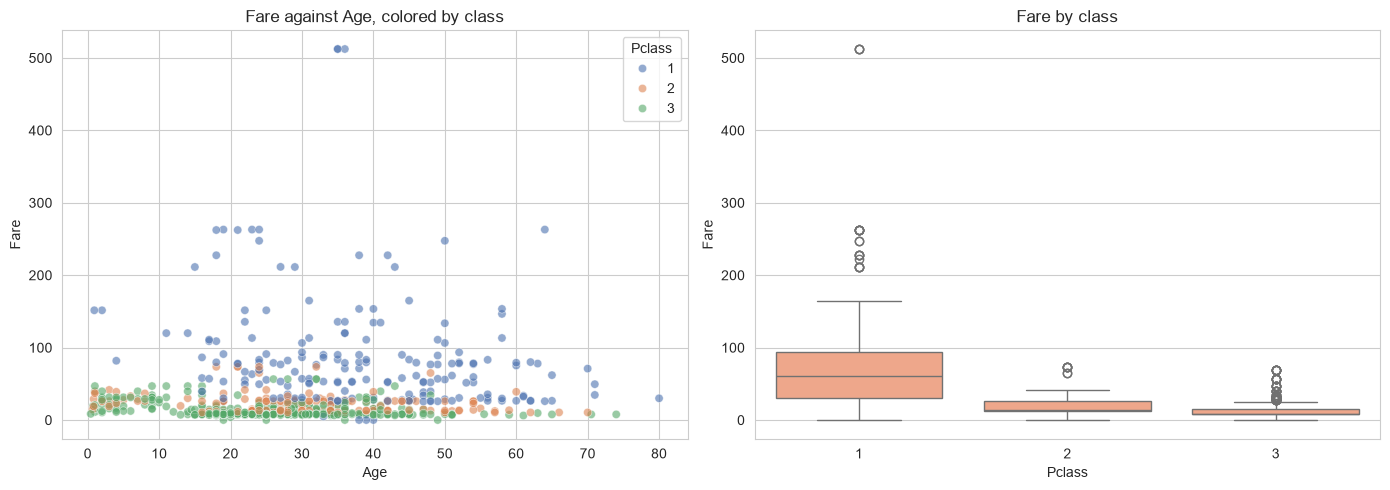

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Pclass", palette="deep", alpha=0.6, ax=axes[0])
axes[0].set_title("Fare against Age, colored by class")
sns.boxplot(data=df, x="Pclass", y="Fare", ax=axes[1], color="lightsalmon")
axes[1].set_title("Fare by class")
plt.tight_layout()
plt.show()

In [20]:
print("Passengers with the highest fares:")
print(df.sort_values("Fare", ascending=False)[["Name", "Pclass", "Age", "Ticket", "Fare", "Survived"]].head(6))
print()
print("Oldest passengers:")
print(df.sort_values("Age", ascending=False)[["Name", "Pclass", "Age", "Survived"]].head(5))

Passengers with the highest fares:
                                   Name  Pclass   Age    Ticket      Fare  \
679  Cardeza, Mr. Thomas Drake Martinez       1  36.0  PC 17755  512.3292   
258                    Ward, Miss. Anna       1  35.0  PC 17755  512.3292   
737              Lesurer, Mr. Gustave J       1  35.0  PC 17755  512.3292   
88           Fortune, Miss. Mabel Helen       1  23.0     19950  263.0000   
438                   Fortune, Mr. Mark       1  64.0     19950  263.0000   
341      Fortune, Miss. Alice Elizabeth       1  24.0     19950  263.0000   

     Survived  
679         1  
258         1  
737         1  
88          1  
438         0  
341         1  

Oldest passengers:
                                     Name  Pclass   Age  Survived
630  Barkworth, Mr. Algernon Henry Wilson       1  80.0         1
851                   Svensson, Mr. Johan       3  74.0         0
493               Artagaveytia, Mr. Ramon       1  71.0         0
96              Goldschmidt, 

**What the code does:** The first cell calculates the IQR limits and the Z-score for Age and Fare and counts the outliers. The second cell draws a scatter plot of Fare against Age colored by class, and box plots of Fare by class. The third cell lists the passengers with the highest fares and the oldest passengers.

**Why this method was used:** Using two methods and two plots gives a more reliable picture than a single rule. Looking at the actual rows of the extreme values is needed to decide if they are genuine or errors.

**What the output means:** For Age, a small number of passengers (11) are above the upper IQR limit of about 65, and only two have a Z-score above 3. For Fare, more than a hundred passengers (about 13 percent) are above the upper IQR limit of about 66, while far fewer have a Z-score above 3, and the largest Z-score is about 9.7. The highest fare, about 512, belongs to three passengers who share the same ticket. The box plot of fare by class shows that first class has a much higher median fare and a wide spread, and also that some outliers disappear when the class is considered.

**Insights:** The two methods disagree for Fare because the distribution is very skewed: the IQR method marks everything in the long tail, while the Z-score method only marks the most extreme values. Most of the high fares are first class tickets, so they are genuine. The three fares of 512 share one ticket, which is a real expensive ticket and not an error. The oldest passengers are old but possible ages. The fares of zero were discussed before and are unusual but valid.

**Effect on the ML pipeline:** I would not remove any of these rows, because they are real passengers and removing them would also remove information about first class passengers. For Fare I would transform the values (log) so that the long tail has less influence, or use a tree based model, which is not sensitive to outliers.

**Decision for each group of outliers**

| Group | Genuine? | Error? | Unusual but valid? | Decision | Reason |
|---|---|---|---|---|---|
| Old passengers (Age above 65) | Yes | No | Yes | Retain | Possible real ages and part of the real population |
| High fares in first class | Yes | No | Yes | Retain, transform Fare | Real expensive tickets, the long tail is natural |
| Three fares of about 512 on one ticket | Yes | No | Yes | Retain | One very expensive shared ticket |
| Fare equal to 0 (15 passengers) | Probably | Possible | Yes | Retain and investigate | Could be crew, guests or missing records, which the data cannot tell |

## 11. Distribution analysis

**Concept:** The distribution shows how the values of a variable are spread.
- A **normal distribution** is a symmetric bell shape in which the mean and the median are equal.
- A **right skewed** distribution has a long tail to the right and a mean above the median. A **left skewed** one is the opposite.
- A **Q-Q plot** compares the data with a normal distribution, and points that follow the straight line mean that the data is close to normal.
- A **log transformation** reduces right skew by shrinking large values more than small values.

**Example:** Incomes are usually right skewed, because a few very high incomes stretch the right tail. A log transformation makes them more symmetric.

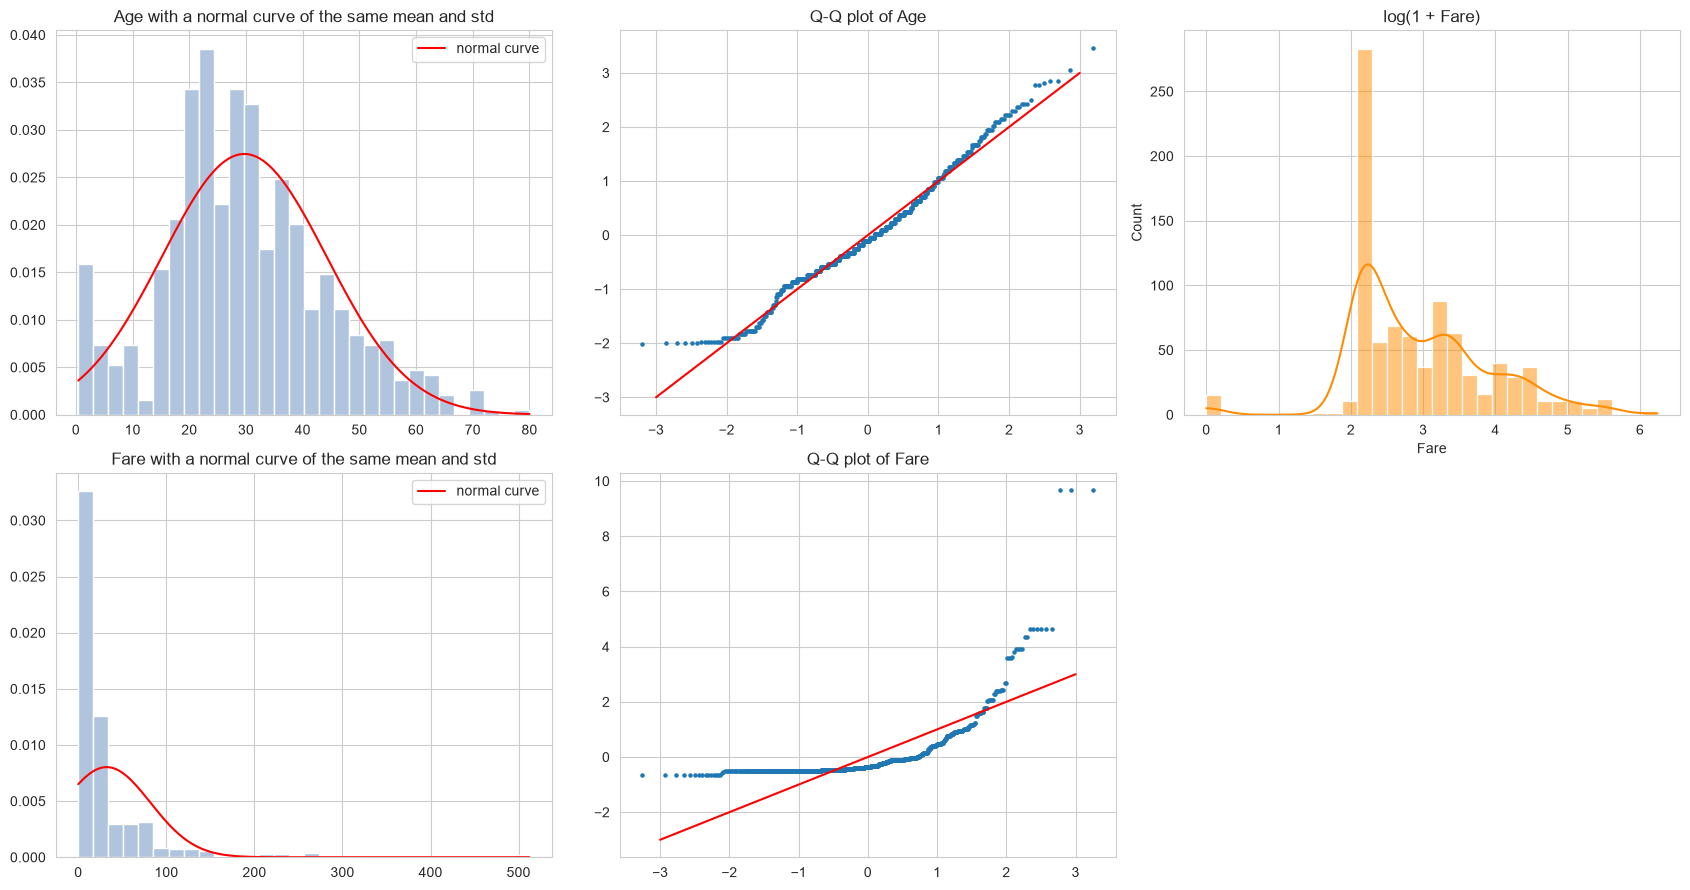

Skewness of Age: 0.39
Skewness of Fare: 4.79
Skewness of log(1 + Fare): 0.39
Skewness of square root of Fare: 2.09


In [21]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for i, col in enumerate(["Age", "Fare"]):
    s = df[col].dropna()
    m, sd = s.mean(), s.std()
    ax = axes[i, 0]
    ax.hist(s, bins=30, density=True, color="lightsteelblue", edgecolor="white")
    x = np.linspace(s.min(), s.max(), 200)
    ax.plot(x, np.exp(-0.5 * ((x - m) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), color="red", label="normal curve")
    ax.set_title(col + " with a normal curve of the same mean and std")
    ax.legend()

    ax = axes[i, 1]
    sorted_s = np.sort(s.values)
    probs = (np.arange(1, len(sorted_s) + 1) - 0.5) / len(sorted_s)
    theoretical = np.array([NormalDist().inv_cdf(p) for p in probs])
    ax.scatter(theoretical, (sorted_s - m) / sd, s=5)
    ax.plot([-3, 3], [-3, 3], color="red")
    ax.set_title("Q-Q plot of " + col)

sns.histplot(np.log1p(df["Fare"]), bins=30, kde=True, ax=axes[0, 2], color="darkorange")
axes[0, 2].set_title("log(1 + Fare)")
axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

print("Skewness of Age:", round(df["Age"].skew(), 2))
print("Skewness of Fare:", round(df["Fare"].skew(), 2))
print("Skewness of log(1 + Fare):", round(np.log1p(df["Fare"]).skew(), 2))
print("Skewness of square root of Fare:", round(np.sqrt(df["Fare"]).skew(), 2))

**What the code does:** For Age and Fare it draws a histogram with a normal curve of the same mean and standard deviation, and a Q-Q plot. It also draws the histogram of log(1 + Fare) and prints the skewness before and after the log and square root transformation. The original data is not changed.

**Why this method was used:** The normal curve and the Q-Q plot show how far each feature is from a normal shape and where it differs. I used log(1 + Fare) because Fare has zero values, and I only tested the transformations without applying them.

**What the output means:** Age follows the normal curve quite well in the middle, with a small extra peak of young children and a slightly longer right tail. In its Q-Q plot the points are close to the line except at the ends. Fare does not follow the normal curve at all, and its Q-Q plot curves far above the line on the right. After the log transformation the skewness falls from about 4.8 to a value close to 0.4, and the histogram becomes much more symmetric. The square root also reduces the skewness but less.

**Insights:** Age is close to normal, and Fare is a clear case of a right skewed variable that a log transformation can fix. The log of the fare also shows a few groups of ticket prices.

**Effect on the ML pipeline:** A log transformation of Fare is a strong candidate for the preprocessing stage, for linear models, KNN and neural networks. Age does not need a transformation. For tree based models neither transformation is needed.

## 12. Correlation analysis

**Concept:** Correlation measures the strength and direction of the straight line relationship between two numerical variables, from -1 (perfect negative) to +1 (perfect positive), and 0 means no linear relationship. A heatmap shows a whole correlation matrix with colors. **Multicollinearity** happens when two input features are strongly correlated with each other, which makes linear model coefficients unstable. Correlation does not prove causation.

**Example:** Ice cream sales and the number of people swimming are correlated because both rise in hot weather, but ice cream does not cause swimming. The hidden cause is the temperature.

          Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
Age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp        -0.04    0.08 -0.31   1.00   0.41  0.16
Parch         0.08    0.02 -0.19   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00


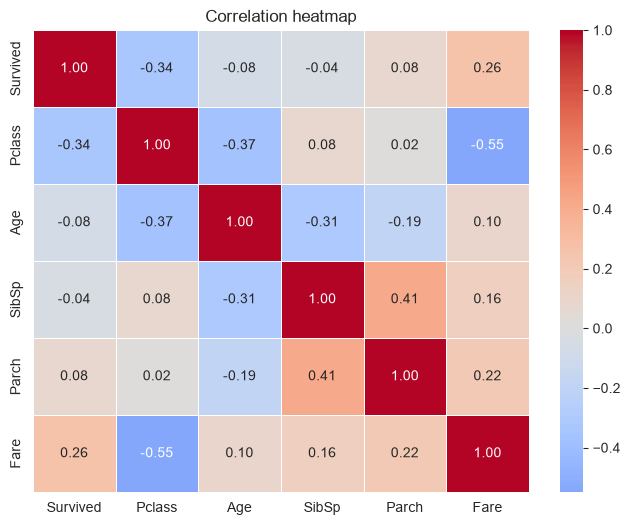


Strongest pairs:
Pclass    Fare     -0.55
SibSp     Parch     0.41
Pclass    Age      -0.37
Survived  Pclass   -0.34
Age       SibSp    -0.31
Survived  Fare      0.26
dtype: float64


In [22]:
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr = df[corr_cols].corr()
print(corr.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=lambda s: s.abs(), ascending=False)
print()
print("Strongest pairs:")
print(pairs.head(6).round(2))

**What the code does:** It calculates the correlation matrix of the numerical columns (including Survived and Pclass), draws it as a heatmap and lists the pairs with the strongest absolute correlation.

**Why this method was used:** A correlation matrix compares all the pairs at once, and the heatmap makes the strong and the negative relationships easy to see.

**What the output means:** The strongest relationship is between Pclass and Fare (about -0.55): the better the class (lower number), the higher the fare. Pclass and Age are correlated at about -0.37, so first class passengers were older. SibSp and Parch have a positive correlation of about 0.41, because families travel together. With Survived, Pclass has about -0.34 and Fare about +0.26, while Age (about -0.08), SibSp and Parch are weak.

**Insights:** Passenger class is the numerical feature most linked to survival, and the relationship with Fare is mostly the same story, because the fare depends on the class. No pair is above 0.7, so there is no severe multicollinearity among these numerical features. The weak correlation of Age with Survived does not mean that age is unimportant, because correlation only measures straight line relationships, and the Sex column is not included in this table.

**Effect on the ML pipeline:** Pclass and Fare overlap, so for a linear model one of them could be enough. Sex is the most important feature in the data, but correlation cannot show it here because it is text. It has to be encoded first, or studied with survival rates, which I do next.

## 13. Target variable analysis

**Concept:** For a classification target, I look at the class counts and percentages and at the class imbalance, which is the ratio of the majority class to the minority class. With imbalance, accuracy alone can be misleading, because a model that always predicts the majority class can still look accurate. A baseline is the performance of such a naive model, and any real model must beat it.

**Example:** If 90 of 100 emails are normal and 10 are spam, a model that says normal for every email is 90 percent accurate but finds no spam.

          count  percent
Survived                
0           549     61.6
1           342     38.4

Imbalance ratio (majority : minority): 1.61 : 1
Accuracy of always predicting did not survive: 61.6 %


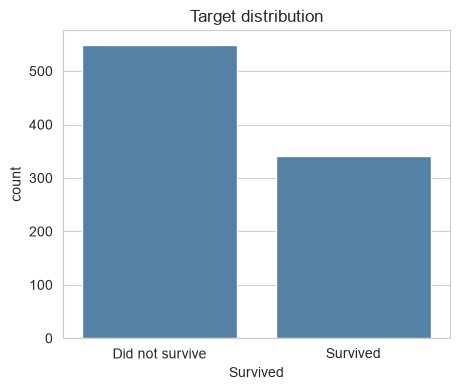

In [23]:
counts = df["Survived"].value_counts()
percent = (df["Survived"].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))
print()
print("Imbalance ratio (majority : minority):", round(counts.max() / counts.min(), 2), ": 1")
print("Accuracy of always predicting did not survive:", round(counts.max() / counts.sum() * 100, 1), "%")

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Survived", color="steelblue")
plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.title("Target distribution")
plt.show()

**What the code does:** It counts the two classes, calculates the percentages and the imbalance ratio, calculates the accuracy of a model that always predicts the majority class, and draws a count plot.

**Why this method was used:** These numbers show how balanced the target is and give the baseline that a real model has to beat.

**What the output means:** 549 passengers did not survive (about 61.6 percent) and 342 survived (about 38.4 percent). The imbalance ratio is about 1.6 to 1, and always predicting that a passenger did not survive would be about 61.6 percent accurate.

**Insights:** The imbalance is mild, much smaller than in problems like fraud detection. Most of the passengers died, so a model must clearly beat 62 percent accuracy to be useful.

**Effect on the ML pipeline:** Accuracy is still usable but it should be supported with precision, recall, F1 and ROC AUC. A stratified split should be used to keep the 38 percent survival share in the training and the test set.

## 14. Features against the target (bivariate analysis)

**Concept:** Bivariate analysis studies the relationship between two variables. For a categorical feature and a binary target, the survival rate of each category (the mean of the 0 and 1 target) compares the groups fairly, even when they have different sizes. The number of passengers in each group must be shown next to the rate, because a rate based on a few people is not reliable. For a numerical feature, box plots or violin plots compare the distribution in the two target classes.

**Example:** In a loan table, comparing the default rate of salaried and self employed customers shows if the job type is related to default.

In [24]:
df_eda = df.copy()

def survival_table(column, data=df_eda):
    t = data.groupby(column, observed=True).agg(passengers=("Survived", "count"), survived=("Survived", "sum"),
                                                survival_rate=("Survived", "mean"))
    t["survival_rate"] = (t["survival_rate"] * 100).round(1)
    return t

for col in ["Sex", "Pclass", "Embarked"]:
    print(col)
    print(survival_table(col))
    print()

Sex
        passengers  survived  survival_rate
Sex                                        
female         314       233           74.2
male           577       109           18.9

Pclass
        passengers  survived  survival_rate
Pclass                                     
1              216       136           63.0
2              184        87           47.3
3              491       119           24.2

Embarked
          passengers  survived  survival_rate
Embarked                                     
C                168        93           55.4
Q                 77        30           39.0
S                644       217           33.7



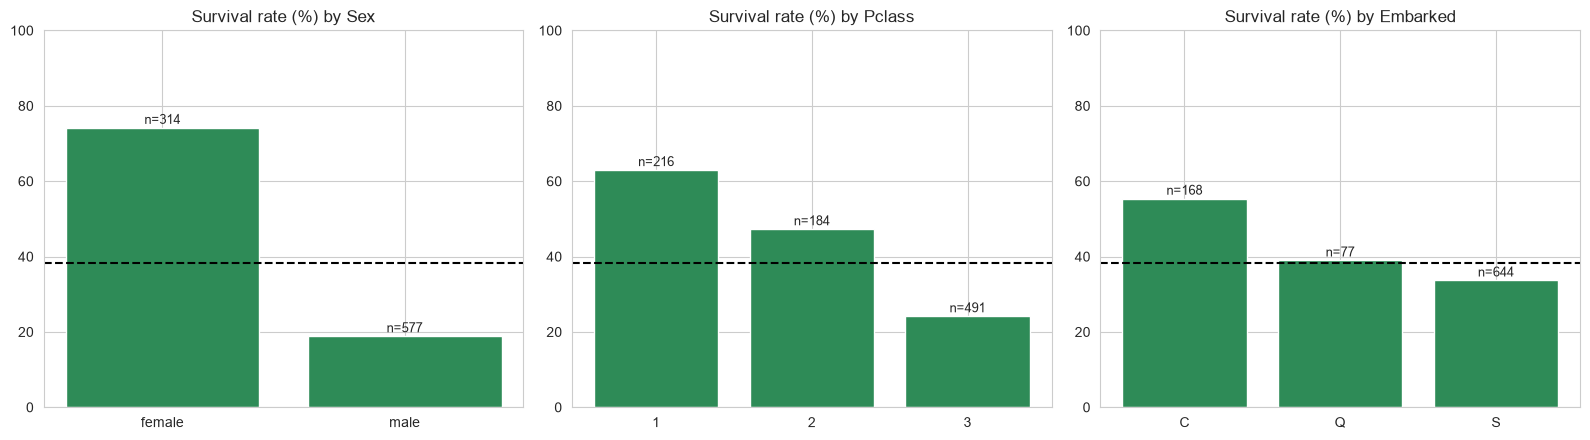

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
overall = df["Survived"].mean() * 100
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    t = survival_table(col)
    ax.bar(t.index.astype(str), t["survival_rate"], color="seagreen")
    for i, (r, n) in enumerate(zip(t["survival_rate"], t["passengers"])):
        ax.text(i, r + 1, "n=" + str(n), ha="center", fontsize=9)
    ax.axhline(overall, color="black", linestyle="--")
    ax.set_title("Survival rate (%) by " + col)
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**What the code does:** It copies the data into df_eda, defines a function that returns the number of passengers, the number of survivors and the survival rate of each category, prints the tables for Sex, Pclass and Embarked and draws bar charts with the group sizes written on the bars and a dashed line at the overall survival rate.

**Why this method was used:** Survival rates compare groups of different sizes fairly, and the group sizes show whether a rate is reliable. Bar charts are the clearest way to compare a few categories.

**What the output means:** About 74 percent of the women survived against about 19 percent of the men. By class, about 63 percent of the first class passengers survived, about 47 percent of the second class and only about 24 percent of the third class. By port, Cherbourg passengers survived more (about 55 percent) than Queenstown (about 39 percent) and Southampton (about 34 percent).

**Insights:** Sex is the strongest feature, followed by class. This agrees with the idea that women and higher class passengers were more likely to be saved. The difference between the ports is probably not a direct effect of the port, because Cherbourg had a larger share of first class passengers, so the port is partly a sign of class.

**Effect on the ML pipeline:** Sex, Pclass and probably Embarked will be important features for a model. The link between Embarked and Pclass is a warning that the importance of a feature can come from another feature.

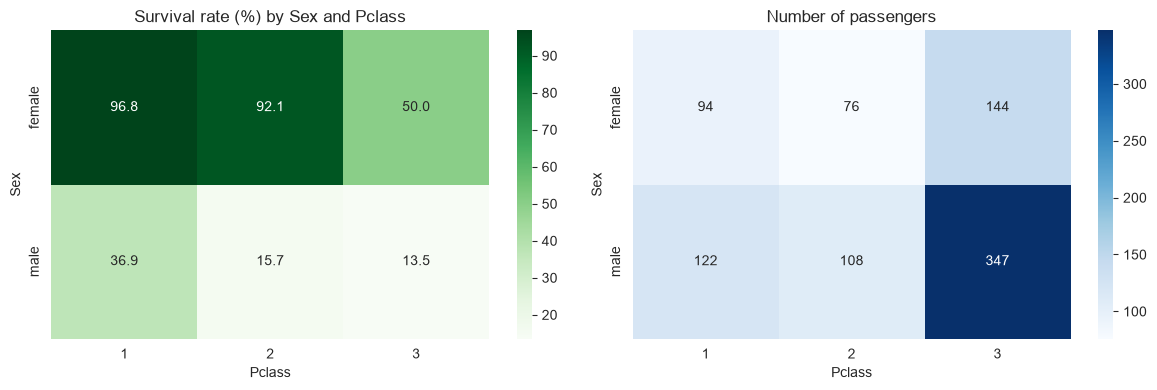

In [26]:
# interaction of sex and class
rate = df_eda.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean") * 100
size = df_eda.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="count")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(rate, annot=True, fmt=".1f", cmap="Greens", ax=axes[0])
axes[0].set_title("Survival rate (%) by Sex and Pclass")
sns.heatmap(size, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Number of passengers")
plt.tight_layout()
plt.show()

**What the code does:** It builds two pivot tables for every combination of sex and class, one with the survival rate and one with the number of passengers, and draws both as heatmaps.

**Why this method was used:** A heatmap shows an interaction between two categorical features: whether the effect of one depends on the other. The count heatmap shows how many passengers each rate is based on.

**What the output means:** Almost all first class and second class women survived (about 97 and 92 percent), while only about half of the third class women survived. Men had low survival in every class, and the lowest in second and third class (about 16 and 14 percent), with about 37 percent in first class.

**Insights:** The effect of class is much stronger for women than for men. Being a woman helped a lot in first and second class, and much less in third class. This is an interaction: the effect of sex depends on the class.

**Effect on the ML pipeline:** A model needs to learn this interaction. Tree based models can learn it, while a linear model needs an interaction feature between Sex and Pclass.

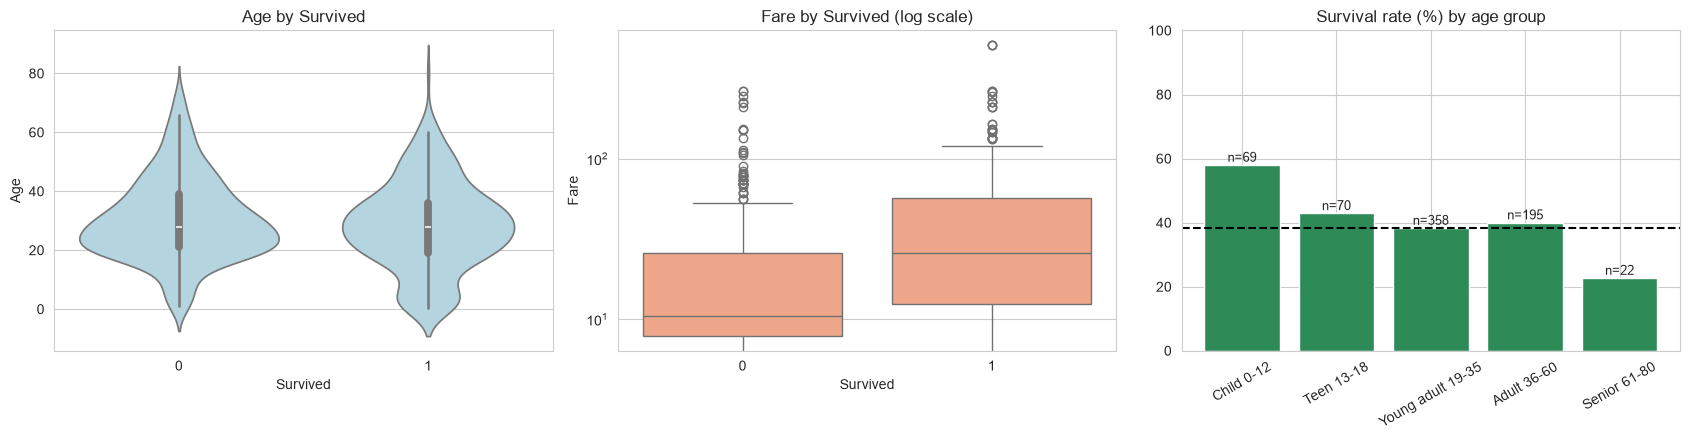

           Age         Fare       
          mean median  mean median
Survived                          
0         30.6   28.0  22.1   10.5
1         28.3   28.0  48.4   26.0


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.violinplot(data=df, x="Survived", y="Age", ax=axes[0], color="lightblue")
axes[0].set_title("Age by Survived")
sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[1], color="lightsalmon")
axes[1].set_yscale("log")
axes[1].set_title("Fare by Survived (log scale)")

df_eda["AgeGroup"] = pd.cut(df_eda["Age"], bins=[0, 12, 18, 35, 60, 80],
                            labels=["Child 0-12", "Teen 13-18", "Young adult 19-35", "Adult 36-60", "Senior 61-80"])
t = survival_table("AgeGroup")
axes[2].bar(t.index.astype(str), t["survival_rate"], color="seagreen")
for i, (r, n) in enumerate(zip(t["survival_rate"], t["passengers"])):
    axes[2].text(i, r + 1, "n=" + str(n), ha="center", fontsize=9)
axes[2].axhline(overall, color="black", linestyle="--")
axes[2].tick_params(axis="x", rotation=30)
axes[2].set_title("Survival rate (%) by age group")
axes[2].set_ylim(0, 100)
plt.tight_layout()
plt.show()

print(df.groupby("Survived")[["Age", "Fare"]].agg(["mean", "median"]).round(1))

**What the code does:** It draws a violin plot of Age and a box plot of Fare (on a log scale because of the skew) for the two target classes, and a bar chart of the survival rate for age groups made with pd.cut. It also prints the mean and median of Age and Fare for each class.

**Why this method was used:** Violin and box plots compare a numerical feature between the two classes, and grouping Age into bands shows a non-linear pattern that the correlation of -0.08 could not show. The log scale makes the box plot of the skewed Fare readable.

**What the output means:** The age distributions of survivors and non-survivors overlap a lot, but the survivors include more small children. The age group chart shows that children had the highest survival rate, and the oldest group the lowest, based on a small group. Survivors paid higher fares, with a higher median fare than non-survivors.

**Insights:** Age alone is a weak separator, but young children were clearly favored. The higher fare of survivors is mostly the effect of first class tickets.

**Effect on the ML pipeline:** Age should be kept and may be more useful as an age group or with a child indicator. Fare is related to survival but overlaps with Pclass.

## 15. Extra exploration: ideas from the raw columns

**Concept:** Sometimes a raw column hides a more useful feature. I test three ideas only to see if they are worth building in the next sprint. I do not add them to the real dataset.
- **Title** taken from Name (Mr, Mrs, Miss, Master) combines sex, age and marital status.
- **Family size** is SibSp plus Parch plus 1 (the passenger).
- **Cabin known** is a yes or no feature made from the mostly empty Cabin column.

**Example:** In a table of customers, the date of birth is less useful for a model than the age made from it, and an address can give a city.

In [28]:
df_eda["Title"] = df_eda["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
common = ["Mr", "Miss", "Mrs", "Master"]
df_eda["TitleGroup"] = df_eda["Title"].where(df_eda["Title"].isin(common), "Other")

df_eda["FamilySize"] = df_eda["SibSp"] + df_eda["Parch"] + 1
df_eda["FamilyGroup"] = pd.cut(df_eda["FamilySize"], bins=[0, 1, 4, 11], labels=["Alone", "Small family 2-4", "Large family 5+"])
df_eda["CabinKnown"] = df_eda["Cabin"].notnull().astype(int)

for col in ["TitleGroup", "FamilyGroup", "CabinKnown"]:
    print(col)
    print(survival_table(col))
    print()

TitleGroup
            passengers  survived  survival_rate
TitleGroup                                     
Master              40        23           57.5
Miss               182       127           69.8
Mr                 517        81           15.7
Mrs                125        99           79.2
Other               27        12           44.4

FamilyGroup
                  passengers  survived  survival_rate
FamilyGroup                                          
Alone                    537       163           30.4
Small family 2-4         292       169           57.9
Large family 5+           62        10           16.1

CabinKnown
            passengers  survived  survival_rate
CabinKnown                                     
0                  687       206           30.0
1                  204       136           66.7



**What the code does:** It extracts the title from the Name text with a regular expression, groups the rare titles into Other, creates the family size and its groups, creates a cabin known indicator, and prints the survival table of each new column.

**Why this method was used:** These tables check if the new columns separate survivors from non-survivors better or differently than the original columns, and the group sizes are printed to avoid reading a rate from a tiny group.

**What the output means:** Men with the title Mr had a survival rate of only about 16 percent, Miss about 70 percent, Mrs about 79 percent and Master (young boys) about 58 percent. Passengers travelling alone survived about 30 percent, small families of 2 to 4 people about 58 percent and large families of 5 or more only about 16 percent. Passengers with a known cabin survived about 67 percent against about 30 percent for the others.

**Insights:** The title is a compact summary of sex and age, and Master shows that young boys were treated more like women and children than like men. Family size has a non-linear effect: travelling alone and in a very large family were both worse than travelling in a small family. Cabin known is mostly a sign of first class.

**Effect on the ML pipeline:** Title, family size groups and cabin known are good candidates for feature engineering. Title will probably overlap with Sex and Age, and cabin known with Pclass, so I will check redundancy.

## 16. Pair plot

**Concept:** A pair plot draws scatter plots for every pair of numerical variables and the distribution of each variable on the diagonal. Coloring the points by the target shows whether the classes can be separated in the space of several features.

**Example:** In the well known iris flower dataset, a pair plot colored by species shows that some species are almost separated, which tells that a simple classifier can work.

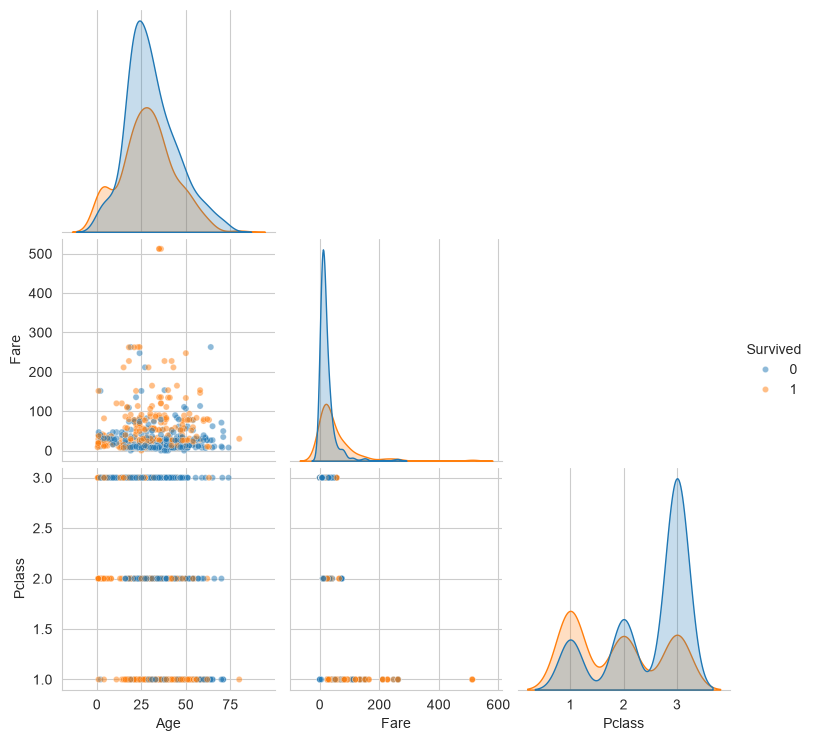

In [29]:
plot_df = df[["Age", "Fare", "Pclass", "Survived"]].dropna()
sns.pairplot(plot_df, hue="Survived", corner=True, plot_kws={"alpha": 0.5, "s": 20})
plt.show()

**What the code does:** It draws a pair plot of Age, Fare and Pclass colored by Survived, using only the rows without missing values.

**Why this method was used:** A pair plot shows all pairs of the main numerical features and the target together, and shows whether any pair separates the two classes.

**What the output means:** The two classes overlap strongly in every scatter plot. The Fare distribution of the survivors has a longer tail to the right. Pclass has only three values, so its plots show bands. Survivors are more frequent in class 1 and at low ages.

**Insights:** No single pair of these numerical features separates survivors from non-survivors. This is the reason why the categorical features (especially Sex) are needed in the model, because the numerical features alone are not enough.

**Effect on the ML pipeline:** A model based only on Age, Fare and Pclass would be limited. A good model should combine them with Sex, Title and family features, and should be able to learn interactions.

## 17. Insights

| Observation | Insight | What it means |
|---|---|---|
| About 74 percent of women survived against about 19 percent of men | Sex is the strongest separator of survival | The evacuation clearly favored women, in line with the rule of saving women and children first |
| Survival fell from about 63 percent in first class to about 24 percent in third class | Social class strongly affected survival | Passengers with more resources had a better chance, possibly because of the location of their cabins and access to the lifeboats, which this data cannot confirm |
| First and second class women survived at over 90 percent, third class women at about 50 percent | Sex and class interact | The advantage of being a woman was much smaller in third class |
| Children had the highest survival among the age groups, and young boys with the title Master survived more than men | Age mattered, especially for the youngest | Children were prioritized |
| Passengers alone and in large families survived less than small families | Family size has a non-linear effect | Small groups could stay together and be evacuated, while large families were slowed down or separated, which is a hypothesis |
| Missing Age and Cabin are linked to class and to lower survival | The missing values carry information | They should not be filled blindly, and a missing indicator may help |
| Fare is extremely right skewed, and first class tickets explain the high values | The outliers in Fare are genuine | The values should be transformed, not removed |
| No numerical feature separates the classes alone | Categorical features are needed | A model should combine Sex, Pclass, Title and family information |

**Important patterns:** sex, class and family size strongly relate to survival.

**Anomalies:** zero fares for 15 passengers, three identical fares of about 512 on one ticket, a very high share of missing values in Cabin.

**Limits:** the data is a historical snapshot of 891 passengers (a sample of the people on board), the relationships are associations and not proofs of cause, and many explanations (for example about the lifeboats) cannot be verified with these columns.

## 18. Recommendations for the preprocessing stage

I only list what should be done. I did not apply any of these steps in this notebook.

| Area | Columns | Recommendation | Reason |
|---|---|---|---|
| Missing values | Age | Impute with the median inside groups (for example by Pclass and Title) and consider a missing indicator | 20 percent is missing, and the missingness is related to class and survival |
| Missing values | Cabin | Do not impute. Drop the column after creating a cabin known indicator | 77 percent is missing |
| Missing values | Embarked | Fill the 2 missing values with the most frequent port | Very few values are missing |
| Duplicates | All | Nothing to remove | No duplicate rows |
| Outliers | Fare, Age | Do not remove rows. Transform Fare | The extreme values are genuine |
| Feature transformation | Fare | Test log(1 + Fare) | Skewness is about 4.8, and zero fares exist |
| Encoding | Sex | Encode as 0 and 1 | Binary feature |
| Encoding | Embarked | One-hot encoding | Nominal feature with 3 categories |
| Encoding | Pclass | Keep as ordinal numbers, or one-hot encode and compare | It has a natural order |
| Feature engineering | Name | Extract the title, then drop Name | The title carries information, the full name does not |
| Feature engineering | SibSp and Parch | Create family size and family groups | The effect of family size is not linear |
| Feature engineering | Age | Test age groups or a child indicator | Children had the highest survival |
| Feature engineering | Sex and Pclass | Test an interaction feature | The effect of sex depends on the class |
| Feature engineering | Fare and Ticket | Consider fare per person using the number of people on a ticket | The fare seems to be per ticket |
| Dropping | PassengerId, Name, Ticket | Drop before training | Identifiers with no general meaning |
| Scaling | Age, Fare (and others) | Standardize for linear, KNN, SVM and neural network models, fitting only on the training data | Very different scales |
| Splitting | Whole data | Use a stratified split, and consider keeping people with the same ticket in the same part | Keeps the class share and avoids leakage between family members |
| Evaluation | Target | Compare with the baseline of about 61.6 percent and use precision, recall, F1 and ROC AUC | Mild imbalance |
| Multicollinearity | Pclass and Fare | Check for redundancy in linear models | Correlation of about -0.55 |

## 19. Final summary

This dataset contains 891 passengers of the Titanic described by 11 features and the target Survived. About 38 percent of the passengers survived. The data is mostly clean: it has no duplicates and no impossible values, but Cabin is missing for 77 percent of the passengers, Age for 20 percent, and Embarked for two passengers, and the missing values are connected with class and survival. Age is close to a normal shape, while Fare is extremely right skewed, with extreme values that are genuine first class fares. The strongest patterns are that women, first class passengers, children and members of small families survived more, and that sex and class interact. Numerical features alone cannot separate the classes, so the categorical features and some engineered features (title, family size, cabin known) are needed. In the next sprint the missing values should be treated carefully, Fare should be transformed, the categorical features encoded and the identifier columns dropped, and the data should be split with stratification.

**What I learned:** A summary statistic can hide a lot, for example a weak correlation of Age with Survived hid the large effect of being a child. Missing values can carry information, outliers can be genuine, and the effect of one feature can depend on another feature. Always showing group sizes next to rates protects me from wrong conclusions.